In [1]:
print("radha")

radha


In [4]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from pydantic import BaseModel,Field
load_dotenv()
groq_api_key = os.getenv("GROQ_API_KEY")

In [5]:
# llm with structured output
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
)

class EvaluationSchema(BaseModel):
    feedback:str = Field(description="Detailed feedback on the essay, highlighting strengths and areas for improvement.")
    score:int = Field(description="A numerical score between 1 and 10, where 10 indicates an excellent essay and 1 indicates a poor essay.")

In [7]:
structured_llm = llm.with_structured_output(EvaluationSchema)

In [9]:
essay = """India and AI Time

Now world change very fast because new tech call Artificial Intel… something (AI). India also want become big in this AI thing. If work hard, India can go top. But if no careful, India go back.

India have many good. We have smart student, many engine-ear, and good IT peoples. Big company like TCS, Infosys, Wipro already use AI. Government also do program “AI for All”. It want AI in farm, doctor place, school and transport.

In farm, AI help farmer know when to put seed, when rain come, how stop bug. In health, AI help doctor see sick early. In school, AI help student learn good. Government office use AI to find bad people and work fast.

But problem come also. First is many villager no have phone or internet. So AI not help them. Second, many people lose job because AI and machine do work. Poor people get more bad.

One more big problem is privacy. AI need big big data. Who take care? India still make data rule. If no strong rule, AI do bad.

India must all people together – govern, school, company and normal people. We teach AI and make sure AI not bad. Also talk to other country and learn from them.

If India use AI good way, we become strong, help poor and make better life. But if only rich use AI, and poor no get, then big bad thing happen.

So, in short, AI time in India have many hope and many danger. We must go right road. AI must help all people, not only some. Then India grow big and world say "good job India"."""

In [12]:

prompt = f"evaluate the following essay and provide feedback and a score between 1 and 10:\n\n{essay}\n\nFeedback:"
op=structured_llm.invoke(prompt)

In [19]:
import rich
from rich.console import Console
from rich.markdown import Markdown

console = Console()
console.print(Markdown(op.feedback))



The essay demonstrates a clear enthusiasm about AI’s potential in India and attempts to cover a range of           
applications—from agriculture to healthcare to governance.  It also recognises legitimate concerns such as digital 
divide, job displacement and privacy.  However, the writing suffers from several problems that limit its           
effectiveness:                                                                                                     

 1 Grammar and Spelling – Frequent errors (e.g., “Artificial Intel…”, “engine‑ear”, “govern”) disrupt readability  
   and undermine credibility.  Proofreading and consistent use of standard English would improve the tone.         
 2 Structure – The piece jumps between ideas without clear signposting.  A more conventional essay format would    
   include an introduction, body paragraphs each focused on a single theme, and a concise conclusion.  Headings or 
   topic sentences would help the reader follow the argument.                                                      
 3 Depth of Analysis – Statements such as “AI help farmer know when to put seed” are too vague.  Adding concrete   
   examples, statistics, or case studies (e.g., the use of AI in precision farming or tele‑medicine in rural India)
   would strengthen the claims.                                                                                    
 4 Coherence and Flow – The transition between paragraphs is abrupt.  Using linking words (“firstly”,              
   “additionally”, “however”) would create smoother progression.                                                   
 5 Tone and Formality – The essay is informal and sometimes colloquial (“big bad thing”).  For an academic or      
   policy‑oriented audience, a more formal register is advisable.                                                  
 6 Evidence of Policy – The mention of “AI for All” is good, but the discussion of data protection laws is         
   superficial.  Referencing India’s Personal Data Protection Bill or the role of the Digital India initiative     
   would add credibility.                                                                                          

Strengths                                                                                                          

 • Clear enthusiasm and positive outlook.                                                                          
 • Recognition of both opportunities and challenges.                                                               
 • Inclusion of multiple sectors (agriculture, health, education, governance).                                     

Areas for Improvement                                                                                              

 • Correct grammatical and spelling errors.                                                                        
 • Organise into clear introduction, body, conclusion.                                                             
 • Provide specific examples and data.                                                                             
 • Use formal academic tone and cohesive devices.                                                                  
 • Cite relevant policies or initiatives.                                                                          

With these revisions, the essay would become a more compelling, persuasive, and credible discussion of AI’s role in
India.

In [20]:
import operator
from typing_extensions import Annotated

class EssayState(TypedDict):
    essay:str
    lang_feedback:str
    doa_feedback:str
    clarity_feedback:str

    individual_score:Annotated[list[int],operator.add]
    avg_score:float
    final_feedback:str


In [25]:
graph=StateGraph(EssayState)

In [26]:
def lang_feedback(state:EssayState):
    prompt=f"Evaluate the language quality of the following essay and provide a feedback and assign a score between 1 and 10:\n\n{state['essay']}"
    output=structured_llm.invoke(prompt)
    return {"lang_feedback":output.feedback,"individual_score":[output.score]}

def doa_feedback(state:EssayState):
    prompt=f"Evaluate the depth of analysis of the following essay and provide a feedback and assign a score between 1 and 10:\n\n{state['essay']}"
    output=structured_llm.invoke(prompt)
    return {"doa_feedback":output.feedback,"individual_score":[output.score]}

def clarity_feedback(state:EssayState):
    prompt=f"Evaluate the clarity of expression of the following essay and provide a feedback and assign a score between 1 and 10:\n\n{state['essay']}"
    output=structured_llm.invoke(prompt)
    return {"clarity_feedback":output.feedback,"individual_score":[output.score]}

def final_feedback(state:EssayState):
    avg_score=sum(state['individual_score'])/len(state['individual_score'])
    prompt=f"based on the following feedbacks, provide a summarised feedback for the essay:\n\nLanguage Feedback: {state['lang_feedback']}\nDepth of Analysis Feedback: {state['doa_feedback']}\nClarity Feedback: {state['clarity_feedback']}"
    feedback=llm.invoke(prompt)
    return {"avg_score":avg_score,"final_feedback":feedback}

In [27]:
graph.add_node("lang_feedback",lang_feedback)
graph.add_node("doa_feedback",doa_feedback)
graph.add_node("clarity_feedback",clarity_feedback)
graph.add_node("final_feedback",final_feedback)

graph.add_edge(START,"lang_feedback")
graph.add_edge(START,"doa_feedback")
graph.add_edge(START,"clarity_feedback")

graph.add_edge("lang_feedback","final_feedback")
graph.add_edge("doa_feedback","final_feedback")
graph.add_edge("clarity_feedback","final_feedback")

graph.add_edge("final_feedback",END)

workflow=graph.compile()

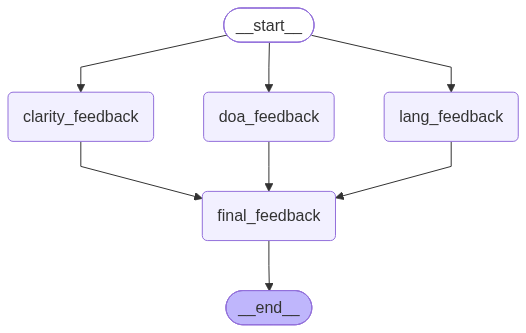

In [28]:
workflow

In [51]:
essay2 = """Education is more than a means of obtaining a degree or securing employment; it is one of the strongest forces for individual and social transformation. It develops knowledge, critical thinking, confidence, and the ability to make informed decisions. For an individual, education expands opportunities and strengthens economic independence. For society, it creates citizens capable of participating responsibly in democratic, economic, and social life.

Moreover, education has a measurable relationship with economic development. According to the World Bank, each additional year of schooling is associated with a significant increase in individual earnings, demonstrating that education can improve both productivity and economic opportunity. Countries that invest consistently in human capital are better positioned to develop skilled workforces, support innovation, and adapt to technological change. Education therefore benefits not only the person sitting in the classroom but also the wider economy.

However, access to education remains deeply unequal. Children from poor families, remote regions, and disadvantaged communities may face barriers such as inadequate schools, financial constraints, limited digital access, and early entry into the workforce. India’s experience with the expansion of school and higher-education access illustrates that increasing enrollment is important, but access alone is insufficient. The quality of teaching, learning outcomes, infrastructure, and affordability must improve alongside enrollment.

Furthermore, education should not be reduced to vocational training. Technical and professional skills are essential in a competitive economy, but subjects such as history, philosophy, literature, and the social sciences develop judgment, empathy, creativity, and cultural awareness. A society needs engineers and doctors, but it also needs citizens who can understand ethical dilemmas, evaluate competing ideas, and recognize the consequences of their actions. The strongest education systems therefore balance employability with intellectual and moral development.

Nevertheless, education is not a guarantee of success by itself. A poorly designed education system can encourage rote memorization, examination pressure, and credentialism rather than genuine learning. Consequently, the objective should not simply be to produce graduates, but to develop people who can learn continuously, solve unfamiliar problems, communicate effectively, and act responsibly.

Ultimately, education is an investment whose returns extend far beyond the classroom. It can expand individual opportunity, strengthen economies, reduce social barriers, and cultivate responsible citizens—but only when access, quality, and relevance are addressed together. The true measure of an education system is therefore not how many certificates it produces, but how effectively it enables people to think, create, contribute, and build a better society.


"""

In [55]:
essay3="""
Education is very important and education is important for everyone because everyone needs education. Education helps people in many ways and it helps people to become educated and knowledgeable. People go to school because school gives education and after school people can go to college and after college they can get a job. Jobs are important because money is important and education helps people get money.

Education is also good for society because educated people are good for society. If people are educated then society becomes educated and when society is educated the country also becomes educated. Education can solve many problems because education solves problems by giving knowledge. There are many problems in the world like poverty, unemployment and pollution, and education can probably solve these problems because educated people can solve problems.

Also, education is important because technology is increasing very much nowadays. Technology is everywhere and people need education to use technology. Students learn computers in schools and computers are useful for jobs. Artificial intelligence is also becoming popular and education can help people learn artificial intelligence. Therefore education is very important in the modern world because the modern world is modern.

However, education also has some problems. Some people do not have education and some people have education. Poor people may not get good education because they are poor, which is a problem. Schools in villages may have fewer facilities than schools in cities. This means education is not equal for everyone. But education is still important because education is important even when education has problems.

In conclusion, education is very important for individuals, society, countries, jobs, technology and the future. Everyone should get education because education makes people educated. Education gives knowledge and knowledge is important. Therefore, education should be promoted everywhere because it is good and important for everyone and it can make the future better.

"""

In [57]:
initial_state={
    "essay":essay3
}
final_state=workflow.invoke(initial_state)

In [58]:
console.print(Markdown(final_state['final_feedback'].content))

Overall Assessment – Score 4/5                                                                                     

The essay shows a clear intent to argue that education is vital, but it falls short in several key areas. Below is 
a concise synthesis of the main strengths and weaknesses, followed by targeted suggestions for improvement.        

-------------------------------------------------------------------------------------------------------------------

1. Language & Style                                                                                                

                                                                                                                   
 Issue                                 Impact                                Suggested Fix                         
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
 Redundancy & Repetition – e.g.,       Wastes words, weakens argument        Replace repeated ideas with synonyms  
 “education is very important …                                              or restructure sentences; combine     
 everyone needs education”                                                   related clauses.                      
 Lack of Depth & Specificity –         Argument feels unsupported            Provide concrete examples,            
 blanket claims like “education can                                          statistics, or case studies to back   
 solve poverty”                                                              each claim.                           
 Limited Vocabulary & Simple           Reduces readability and language      Introduce varied lexical items and    
 Sentences                             control                               mix simple with compound/complex      
                                                                             sentences.                            
 Grammar & Word Choice – awkward       Distracts readers                     Use idiomatic expressions             
 phrasing such as “technology is                                             (“technology is pervasive today”) and 
 increasing very much nowadays”                                              precise verbs.                        
 Logical Flow – minimal transitions    Makes the piece feel disjointed       Insert linking words (however,        
 between paragraphs                                                          furthermore, consequently) and        
                                                                             thematic connectors.                  
 Redundant Conclusion – repeats        Misses opportunity to synthesize      Summarize key points and offer a      
 earlier ideas                                                               final insight or call‑to‑action.      
                                                                                                                   

-------------------------------------------------------------------------------------------------------------------

2. Depth of Analysis                                                                                               

                                                                                                                   
 Issue                                Impact                       Suggested Fix                                   
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
 Superficial, tautological arguments  No real persuasion           Develop a clearer thesis and articulate         
                                                                   distinct arguments.                             
 No evidence or counter‑points        Lacks credibility            Cite research, statistics, or expert opinions;  
                                                 

In [59]:
final_state['avg_score'],final_state['individual_score']

(3.6666666666666665, [4, 3, 4])